# TCH 多模式 24 小时降水集成

起报 2026052300，预报时效 060 小时。七个模式的 24 小时降水预报插到 0.1° 网格后，估计 BTCH 权重并加权得到 TCH 集成预报。同一有效时刻的实况是 Micaps3 站点 24 小时降水量，北京时 2026052520，与各模式预报、TCH 画在同一色标下。

## 原理

按起报时次和预报时效读取各模式 24 小时累积降水，插值到统一网格，合并成带 member 维的集合。`TchWeightPlugin` 把各模式场与参考场展平，用预报减参考的样本协方差估计各模式不确定度。权重与该模式以外各模式不确定度的平方乘积成正比，再归一化：单个模式不确定度越小，权重越大。`TchBlendPlugin` 逐格点做加权和，得到 TCH 集成场。本示例不做站点插值。全国 0.1° 掩膜参与权重估计时的有效区。

## 参数

| 参数 | 本示例 | 含义 |
| --- | --- | --- |
| `model_list` | ECMWF、德国 GFS、NCEP GFS、GRAPES 3km、北京、广州、上海 | 参与集成的模式，顺序与权重一致 |
| `ipt_type` | `m4` | 输入为 Micaps4。预设是 `nc`，没有 nc 时用 m4 |
| `grid_lon` / `grid_lat` | 70–140°E、0–60°N，0.1° | 统一插值网格 |
| `fcst_hours` | 60 | 预报时效（小时）。预设还有 36、84 |
| `maskout_file` | `resource/maskout_cn_0.1_2.dat` | 全国掩膜，701×601 |
| 实况 | `Observation/r24/sfc/YYMMDDHH.000` | 北京时命名。时刻为起报 UTC 加 8 小时再加时效 |

调用里没有写明的项，先取 `resource/conf.ini` 的非空值，再取代码预设。


ecmwf  不确定度 5.6172  权重 0.0787
german_gfs_hr  不确定度 5.6327  权重 0.0783
ncep_gfs_hr  不确定度 5.3607  权重 0.0864
grapes_3km  不确定度 7.6535  权重 0.0424
beijing_mr  不确定度 5.2213  权重 0.0911
guangzhou_mr  不确定度 2.7719  权重 0.3231
shanghai_mr  不确定度 2.8762  权重 0.3001
起报 2026052300  预报时效 060h  实况 2026052520（北京时）  站点数 922  窗口内最大 253.8 mm  TCH最大 83.1 mm
窗口 22.1–36.0N, 109.2–127.1E


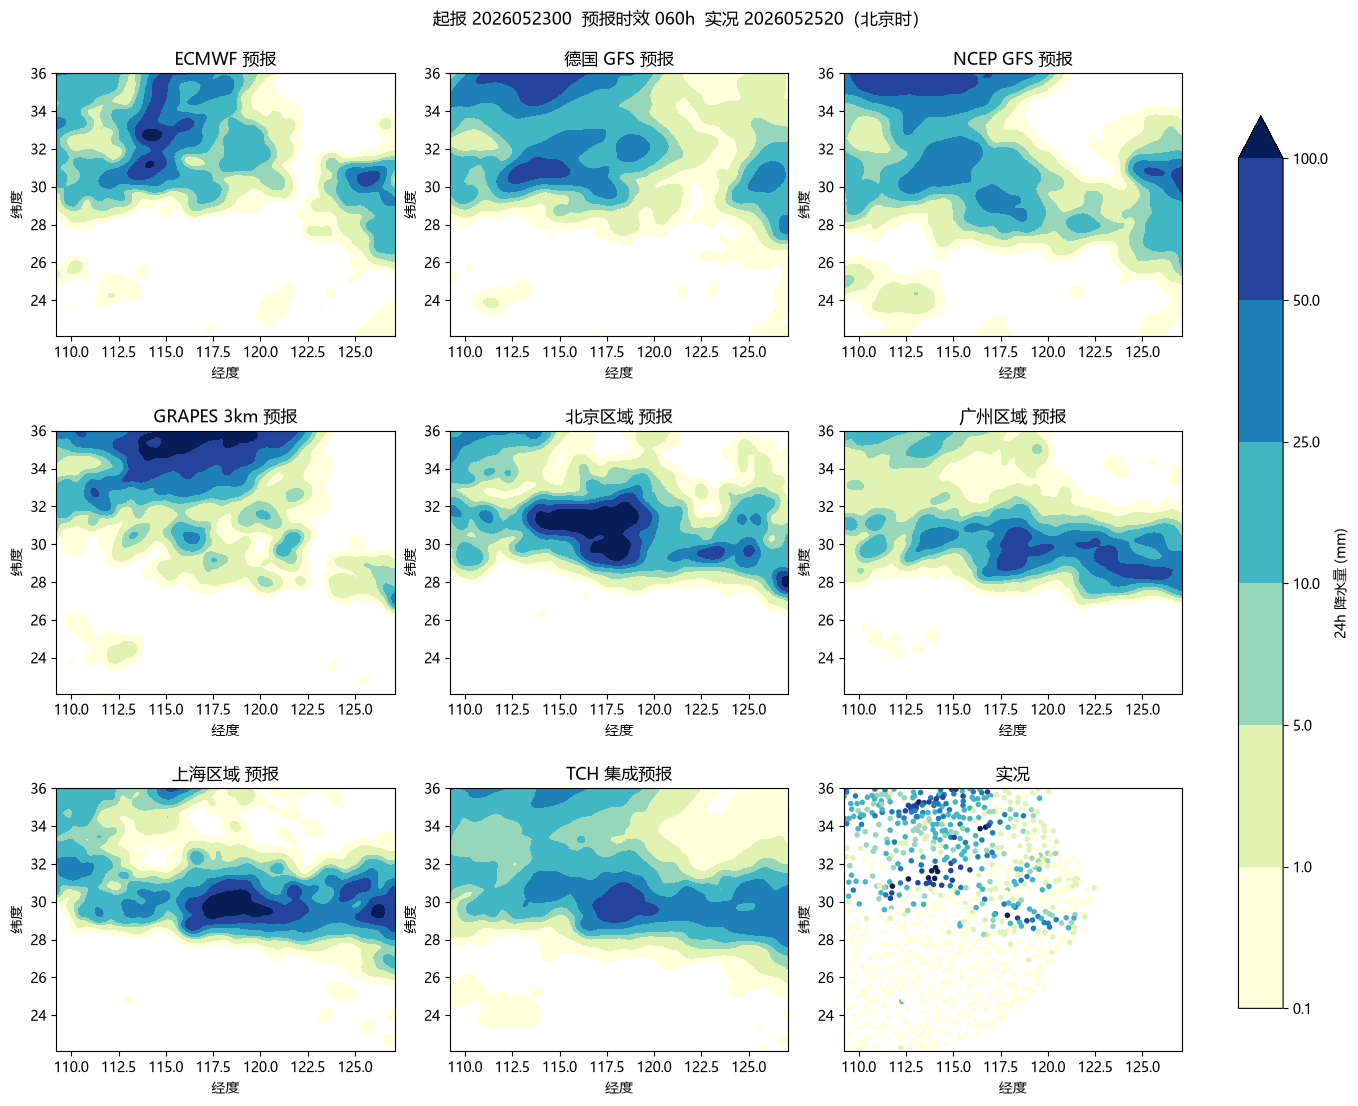

In [1]:
import contextlib
import io
import sys
import types
from datetime import datetime, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager
from matplotlib.colors import BoundaryNorm
from scipy.ndimage import uniform_filter

with contextlib.redirect_stdout(io.StringIO()):
    import meteva_base

meteva = types.ModuleType("meteva")
meteva.base = meteva_base
sys.modules["meteva"] = meteva
sys.modules["meteva.base"] = meteva_base

PKG = Path(r"d:\Work\NIMM_pip_repos\00temp\multi_rain_TCH_blending")
for path in (PKG, PKG / "src"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

from pre_fcst_tch_realtime import get_model_data, prepare_ensemble_for_tch
from tch_blend_plugin import TchBlendPlugin
from tch_weight_plugin import TchWeightPlugin

DATA_DIR = Path(r"D:\data1\zhongzhuan\nimm_test_data\multi_rain_mait24_blending\test_data")
MODELS = [
    "ecmwf",
    "german_gfs_hr",
    "ncep_gfs_hr",
    "grapes_3km",
    "beijing_mr",
    "guangzhou_mr",
    "shanghai_mr",
]
LABELS = {
    "ecmwf": "ECMWF 预报",
    "german_gfs_hr": "德国 GFS 预报",
    "ncep_gfs_hr": "NCEP GFS 预报",
    "grapes_3km": "GRAPES 3km 预报",
    "beijing_mr": "北京区域 预报",
    "guangzhou_mr": "广州区域 预报",
    "shanghai_mr": "上海区域 预报",
    "tch": "TCH 集成预报",
}
INITIAL = datetime(2026, 5, 23, 0)
LEAD = 60
LEVELS = [0.1, 1, 5, 10, 25, 50, 100]
NORM = BoundaryNorm(LEVELS, ncolors=256, extend="max")

font = Path(r"C:\Windows\Fonts\msyh.ttc")
if font.is_file():
    font_manager.fontManager.addfont(str(font))
    plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

mask = np.fromfile(PKG / "resource" / "maskout_cn_0.1_2.dat", dtype=np.float32).reshape((601, 701), order="C")
with contextlib.redirect_stdout(io.StringIO()):
    qpf = get_model_data(
        str(DATA_DIR) + "\\",
        MODELS,
        INITIAL,
        LEAD,
        [70.0, 140.0, 0.10],
        [0.0, 60.0, 0.10],
        ipt_type="m4",
    )
members = [str(name) for name in qpf["member"].data]
flat, _ndim, _ny, _nx = prepare_ensemble_for_tch(qpf, mask.reshape(701 * 601))
with contextlib.redirect_stdout(io.StringIO()):
    weight_out = TchWeightPlugin().process(flat)
weights = weight_out["weights"]
for name, err, weight in zip(members, weight_out["uct"], weights):
    print("%s  不确定度 %.4f  权重 %.4f" % (name, err, weight))

tch = TchBlendPlugin().process(qpf, weights)["qpf_combine"]
field = np.squeeze(np.asarray(tch.values))
smooth = uniform_filter(np.nan_to_num(field, nan=0.0), size=21)
gy, gx = np.gradient(smooth)
score = smooth * (np.hypot(gy, gx) + 0.02)
iy, ix = np.unravel_index(int(np.nanargmax(score)), score.shape)
nlat, nlon = 140, 180
y0 = int(np.clip(iy - nlat // 2, 0, field.shape[0] - nlat))
x0 = int(np.clip(ix - nlon // 2, 0, field.shape[1] - nlon))
y1, x1 = y0 + nlat, x0 + nlon
lat = np.asarray(tch.lat.values[y0:y1], dtype=float)
lon = np.asarray(tch.lon.values[x0:x1], dtype=float)
lat0, lat1 = float(np.min(lat)), float(np.max(lat))
lon0, lon1 = float(np.min(lon)), float(np.max(lon))

def read_micaps3_rain(path):
    encoding, _ = meteva_base.io.get_encoding_of_file(str(path), read_rows=1)
    strs = []
    skip_num = 0
    nline = 0
    with open(path, "r", encoding=encoding) as file:
        while True:
            skip_num += 1
            strs.extend(file.readline().split())
            if len(strs) > 8:
                nline = int(float(strs[8]))
            if len(strs) > 11 + nline:
                nregion = int(float(strs[11 + nline]))
                if len(strs) == nline + 2 * nregion + 14:
                    break
    sta = pd.read_csv(
        path, skiprows=skip_num, sep=r"\s+", header=None, usecols=[0, 1, 2, 4], encoding=encoding,
    )
    sta.columns = ["id", "lon", "lat", "data0"]
    return sta[sta["data0"] < 9990]

valid_bjt = INITIAL + timedelta(hours=8 + LEAD)
ob_path = DATA_DIR / "Observation" / "r24" / "sfc" / ("%s.000" % valid_bjt.strftime("%y%m%d%H"))
ob = read_micaps3_rain(ob_path)
in_box = (ob["lat"] >= lat0) & (ob["lat"] <= lat1) & (ob["lon"] >= lon0) & (ob["lon"] <= lon1)
ob_box = ob.loc[in_box]
print(
    "起报 %s  预报时效 %03dh  实况 %s（北京时）  站点数 %d  窗口内最大 %.1f mm  TCH最大 %.1f mm"
    % (
        INITIAL.strftime("%Y%m%d%H"),
        LEAD,
        valid_bjt.strftime("%Y%m%d%H"),
        len(ob_box),
        float(ob_box["data0"].max()) if len(ob_box) else float("nan"),
        float(np.nanmax(field)),
    )
)
print("窗口 %.1f–%.1fN, %.1f–%.1fE" % (lat0, lat1, lon0, lon1))

panels = []
for name in members:
    data = np.squeeze(np.asarray(qpf.sel(member=name).values))[y0:y1, x0:x1]
    panels.append((data, LABELS[name]))
panels.append((field[y0:y1, x0:x1], LABELS["tch"]))

fig, axes = plt.subplots(3, 3, figsize=(13.5, 11), constrained_layout=True)
mesh = None
for ax, (data, title) in zip(axes.ravel(), panels):
    mesh = ax.contourf(lon, lat, np.clip(data, 0, None), levels=LEVELS, cmap="YlGnBu", norm=NORM, extend="max")
    ax.set_title(title)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("经度")
    ax.set_ylabel("纬度")

ax = axes.ravel()[-1]
ax.scatter(
    ob_box["lon"],
    ob_box["lat"],
    c=ob_box["data0"],
    s=16,
    cmap="YlGnBu",
    norm=NORM,
    linewidths=0,
)
ax.set_xlim(lon0, lon1)
ax.set_ylim(lat0, lat1)
ax.set_title("实况")
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("经度")
ax.set_ylabel("纬度")
fig.colorbar(mesh, ax=axes, shrink=0.85, label="24h 降水量 (mm)")
fig.suptitle("起报 %s  预报时效 %03dh  实况 %s（北京时）" % (
    INITIAL.strftime("%Y%m%d%H"), LEAD, valid_bjt.strftime("%Y%m%d%H"),
))
plt.show()
